# DATA MINING PROJECT: ACDC CUSTOMER SEGMENTATION

Group 20

## Data Exploration and initial analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


dfo = pd.read_csv("acdc_dataset.csv", sep=";")

# Criar uma cópia do dataset original antes de iniciar o tratamento para garantir que temos como voltar atrás
df = dfo.copy()

In [2]:
print(f'O dataset original é composto por {df.shape[0]} utilizadores, os quais têm a si associados {df.shape[1]} atributos:\n\n {df.columns}.')

O dataset original é composto por 15465 utilizadores, os quais têm a si associados 31 atributos:

 Index(['member_id', 'age', 'gender', 'industry', 'country', 'is_team_account',
       'n_colleagues_on_account', 'plan_tier', 'plan_days_per_week',
       'membership_start', 'membership_end', 'last_badge_swipe',
       'days_since_last_visit', 'total_visits', 'avg_weekly_visits',
       'entitled_visits_last_period', 'actual_visits_last_period',
       'meeting_room_hours', 'event_space_hours', 'guest_passes_issued',
       'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes',
       'uses_print', 'uses_mail_handling', 'uses_phone_booths',
       'uses_day_passes', 'uses_storage', 'uses_bike_locker', 'n_renewals',
       'lifetime_value'],
      dtype='object').



Para compreender melhor aquilo que simbolizam estes atributos, nomeadamente o tipo de dados e outras informações relevantes para lá da descrição fornecida no Anexo, segue:


In [3]:
df.head(10)

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,...,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,...,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,...,False,False,0,False,False,False,False,False,1,4486.17
3,CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,...,False,False,0,False,False,False,False,False,0,258.63
4,CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,...,False,False,0,False,False,True,False,False,0,335.74
5,CW000006,39.0,Male,Health,Portugal,False,0,flex,3,2021-05-31,...,False,False,1,True,False,False,False,False,0,413.17
6,CW000007,23.0,Female,Unknown,Portugal,True,2,hot_desk,2,2022-01-17,...,False,True,0,False,False,False,False,False,0,257.95
7,CW000008,33.0,Male,Information Technology,Portugal,True,3,flex,3,2021-03-28,...,False,False,0,False,False,False,True,False,0,4636.8
8,CW000009,30.0,Male,Other,Portugal,False,0,flex,3,2023-08-12,...,True,False,0,False,False,False,False,False,0,281.37
9,CW000010,44.0,Male,Consulting,Portugal,False,0,dedicated_desk,5,2022-06-06,...,False,True,1,True,True,False,True,False,1,8741.88


Já são visíveis alguns problemas relativamente à consistência dos dados ("portugal" em vez de "Portugal", "HOT_DESK" em vez de "hot_desk", "F" em vez de "Female", entre muitos outros. 

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  object 
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  object 
 3   industry                     15465 non-null  object 
 4   country                      15035 non-null  object 
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  object 
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  object 
 10  membership_end               15465 non-null  object 
 11  last_badge_swipe             15465 non-null  object 
 12  days_since_last_visit        15465 non-null  int64  
 13  total_visits    

À primeira vista, as variáveis ```age```, ```entitled_visits_last_period``` e ```uses_print``` apresentam um ```dtype``` incorreto, de acordo com a descrição fornecida no enunciado: a primeira deveria ser um ```int64``` (a idade toma sempre um valor inteiro), a segunda um ```int64``` (não existem visitas decimais) e a última um ```bool``` (à semelhança das restantes variáveis que envolvem um número de usos). Naturalmente, estes problemas serão analisados e resolvidos ao longo deste notebook. A variável `lifetime_value` também apresenta um `dtype` incorreto: tratando-se de um valor de receita total, devia ser um `float` e não uma `string`.

De modo a complementar esta análise, parece-nos importante, para já, compreender como se comportam as variáveis numéricas, a fim de detectar, por exemplo, valores anómalos. Para tal, usamos o método ```.describe()```. As variáveis categóricas serão devidamente tratadas posteriormente.

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.858724,10.394649,1.0,29.00,34.00,40.00,149.00
n_colleagues_on_account,15465.0,0.537019,1.177668,-1.0,0.00,0.00,1.00,9.00
plan_days_per_week,15465.0,3.387262,1.458818,0.0,2.00,3.00,5.00,9.00
days_since_last_visit,15465.0,117.109279,275.532807,-956.0,4.00,13.00,55.00,1212.00
total_visits,15465.0,110.406531,182.939340,-112.0,8.00,34.00,132.00,6530.00
avg_weekly_visits,15465.0,1.777214,1.937515,0.0,0.71,1.42,2.41,47.40
entitled_visits_last_period,15465.0,27.517393,13.480235,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.800970,11.387207,0.0,5.00,10.00,20.00,60.00
meeting_room_hours,14167.0,33.075570,428.169678,-56.6,0.00,0.00,7.20,41220.00
event_space_hours,15465.0,5.117220,26.013097,-13.5,0.00,0.00,0.00,602.80


Há vários potenciais problemas que saltam à vista aquando da análise da tabela acima:

1. A variável ```age``` apresenta valores nitidamente atípicos: tendo em conta o contexto apresentado, não parecem ser admissíveis membros com idade inferior a 18 anos, assim como também é irrealista, por exemplo, pensar que um ser humano vive 149 anos;
2. As variáveis ```n_colleagues_on_account```, ```days_since_last_visit```, ```total_visits```, ```meeting_room_hours```, ```guest_passes_issued``` e ```n_renewals``` apresentam um valor mínimo negativo, o que é um absurdo neste contexto;
3. Os valores máximos das variáveis ```days_since_last_visit```, ```total_visits``` e ```meeting_room_hours```, por exemplo, parecem *outliers* (ou até valores introduzidos incorretamente), contudo, não tendo certezas para já, carecem de uma análise posterior. Esta intuição deve-se, para já, ao contexto e, ainda, ao elevado valor do desvio padrão.

## Tratamento de inconsistências das variáveis

Uma vez que o método ```.describe()``` não forneceu, por nosso desejo, informações sobre as variáveis categóricas, é uma mais-valia começar por analisá-las. Neste caso, decidimos começar por explorar as mais simples, como aquelas cujo número de valores que pode tomar é limitado (por exemplo, género). Uma forma rápida de o fazer, para já, é verificar que valores tomam atualmente, através da função ```.unique()```. De seguida, explorar-se-á algumas variáveis numéricas que, dados os *outputs* anteriores, parecem problemáticas.

### Análise da variável `gender`

In [6]:
df["gender"].unique()

array(['Female', 'Male', 'F', 'Other', nan, ' Female', 'M', 'male',
       ' Male', 'other', ' Other', 'female', 'O'], dtype=object)

In [7]:
df["gender"].value_counts()

gender
Female     7414
Male       6172
Other       465
female      169
F           143
 Female     141
M           138
male        132
 Male       129
other        15
 Other        9
O             8
Name: count, dtype: int64

In [8]:
print(f"Existem {df['gender'].isna().sum()} NA values, o que já era aliás sabido pela informação dada via-instrução .info().")

Existem 530 NA values, o que já era aliás sabido pela informação dada via-instrução .info().


Assumindo ```Other```como um possível valor que a variável ```gender``` pode assumir, existem apenas três valores possíveis. Sendo perfeitamente percetível que "F" e "M" referir-se-ão aos sexos feminino e masculino, respetivamente, bem como os casos em que o valor é introduzido com letras minúsculas e/ou com espaçamentos desnecessários, podemos acionar a função ```.replace()```. 

Como os valores ```Female```, ```Male``` e ```Other``` ocupam as primeiras posições, vamos uniformizar o *dataset* para esses valores, em vez de, por exemplo, assumir as iniciais (```F```, ```M``` e ```O```).

In [9]:
df["gender"] = df["gender"].replace({
    "F": "Female",
    " Female": "Female",
    "female": "Female"
})

df["gender"] = df["gender"].replace({
    "M": "Male",
    " Male": "Male",
    "male": "Male"
})

df["gender"] = df["gender"].replace({
    "O": "Other",
    " Other": "Other",
    "other": "Other"
})

Para concluir que as alterações foram bem sucedidas, acione-se a instrução ```.unique()``` novamente:

In [10]:
df["gender"].unique()

array(['Female', 'Male', 'Other', nan], dtype=object)

Uma vez corrigida, esta variável deve ser tratada como uma **variável categórica nominal**:

In [11]:
df["gender"] = df["gender"].astype("category")

### Análise da variável `plan_tier`

A variável `plan_tier` contém somente cinco categorias distintas, fornecidas no Anexo:

- `hot_desk`
- `flex`
- `dedicated_desk`
- `full_time`
- `private_office`

In [12]:
df["plan_tier"].unique()

array(['flex', 'HOT_DESK', 'hot_desk', 'dedicated_desk', 'full_time',
       'private_office', 'Hot Desk', 'dedicateddesk', nan, 'FULL_TIME',
       'hotdesk', 'Flex', 'FLEX', 'fulltime', 'privateoffice',
       'Full Time', 'DEDICATED_DESK', 'Dedicated Desk', 'Private Office',
       'PRIVATE_OFFICE'], dtype=object)

À semelhança do que fizemos para o tratamento da variável `gender`, é importante uniformizar a maneira como os valores das variáveis são computados no *dataset* já que o *Python* é muito sensitivo. 

In [13]:
df["plan_tier"] = df["plan_tier"].replace({
    "HOT_DESK": "hot_desk",
    "hotdesk": "hot_desk",
    "Hot Desk": "hot_desk"
})

df["plan_tier"] = df["plan_tier"].replace({
    "FLEX": "flex",
    "Flex": "flex"
})

df["plan_tier"] = df["plan_tier"].replace({
    "DEDICATED_DESK": "dedicated_desk",
    "Dedicated Desk": "dedicated_desk",
    "dedicateddesk": "dedicated_desk"
})

df["plan_tier"] = df["plan_tier"].replace({
    "Full Time": "full_time",
    "FULL_TIME": "full_time",
    "fulltime": "full_time"
})

df["plan_tier"] = df["plan_tier"].replace({
    "privateoffice": "private_office",
    "Private Office": "private_office",
    "PRIVATE_OFFICE": "private_office"
})

In [14]:
df["plan_tier"].unique()

array(['flex', 'hot_desk', 'dedicated_desk', 'full_time',
       'private_office', nan], dtype=object)

Uma vez que os valores já estão corrigidos e na descrição consta uma relação de importância clara entre os diferentes tipos de plano, é mais adequado representar esta variável como uma **variável categórica ordinal**. 

In [15]:
df["plan_tier"] = pd.Categorical(
    df["plan_tier"],
    categories=[
        "hot_desk",
        "flex",
        "dedicated_desk",
        "full_time",
        "private_office"
    ],
    ordered=True
)

### Análise da variável `uses_print`
Ao contrário das restantes variáveis descritivamente *booleanas*, o `dtype` devolvido pela função `.describe()` revela que pelo menos um dos valores introduzidos não é `True` nem `False`. Confirme-se esse mesmo facto e corrija-se o problema:

In [16]:
df["uses_print"].unique()

array([0, 1])

Afinal, a variável `uses_print` encontrava-se codificada em formato binário (`0` para Falso e `1` para Verdadeiro). 
Como não existe qualquer valor diferente destes dois, é possível converter automaticamente o `dtype` para `bool`:

In [17]:
df["uses_print"] = df["uses_print"].astype(bool)

In [18]:
df["uses_print"].unique()

array([False,  True])

### Análise da variável `lifetime_value`
Pela descrição presente no Anexo, esta variável representa a receita total que cada membro gerou ao espaço de *cowork*. Consequentemente, o seu `dtype` deveria ser `float` e não `str`, o que constava na análise do método `.describe()`:

In [19]:
df["lifetime_value"].unique()

array(['4477.97', '165.86', '4486.17', ..., '2031.02', '784.69',
       '8358.39'], shape=(11861,), dtype=object)

In [20]:
df["lifetime_value"].apply(type).value_counts()

lifetime_value
<class 'str'>      14425
<class 'float'>     1040
Name: count, dtype: int64

In [21]:
df["lifetime_value"] = df["lifetime_value"].astype(str)

Como existem 14425 `str`, o mais provável é que haja símbolos ou outros elementos que estejam a contaminar os dados. Para confirmar ou refutar esta teoria, aplique-se a instrução `str.extractall`.


In [22]:
df["lifetime_value"].astype(str).str.extractall(r"([^\d\.])")[0].value_counts()

0
n    2080
a    1040
      291
€     291
,     111
-      82
Name: count, dtype: int64

Efetivamente, os dados estão contaminados, pelo que é necessário "limpá-los" e, finalmente, convertê-los para `float`. 

In [23]:
df["lifetime_value"] = df["lifetime_value"].str.replace(r"[€,\s-]", "", regex=True)
df["lifetime_value"] = pd.to_numeric(df["lifetime_value"], errors="coerce")
df["lifetime_value"].apply(type).value_counts()

lifetime_value
<class 'float'>    15465
Name: count, dtype: int64

### Análise das variávels `age` e `guest_passes_issued`
Depreende-se da descrição dada que as variáveis supracitadas representam, respetivamente, a idade do utilizador e o número de *guess passes* entregues por si, pelo que ambas devem admitir somente valores inteiros, ao contrário do que o método `.describe()` revela. 

In [24]:
df["age"].unique()

array([ 38.,  43.,  45.,  39.,  23.,  33.,  30.,  44.,  37., 131.,  20.,
        40.,  32.,  21.,  29.,  25.,  28.,  51.,  41.,  nan,  31.,  42.,
        34.,  36.,  50.,  24.,  19.,  47.,  54.,  26.,  53.,  27.,  46.,
        18.,  48.,  63.,  35.,  22.,  59.,  49.,   4.,   3.,  58.,  72.,
         9.,   8.,  57.,  52.,  73., 132.,  60.,  55., 144.,  61.,   1.,
         6., 141.,   2.,   7., 137.,  66., 147., 140., 142.,  56.,  62.,
       145.,   5.,  65.,  83.,  14., 138., 136., 146., 134.,  70.,  74.,
        93.,  92., 143., 139.,  91.,  64., 149., 135.])

In [25]:
df["age"].isna().sum()

np.int64(558)

In [26]:
df["guest_passes_issued"].unique()

array([ 18.,   0.,   1.,  37.,  nan,  23.,  57.,  17.,  14.,   2.,   5.,
        28., 189.,  34.,  30.,  35.,  12.,   3.,  19.,  10.,  55.,  58.,
        61.,  91.,   4.,  24., 100.,  15.,  13.,  43.,  54., 135.,  68.,
        65.,  16.,  25.,  74.,  20.,  45.,  40.,  46.,   9., 200.,  52.,
        72.,  26.,   8.,  78.,   6., 132.,   7.,  85.,  49.,  84.,  22.,
        64.,  21.,  71.,  27.,  48.,  62.,  77.,  44., 101.,  53., 116.,
       147., 127.,  60.,  32., 228.,  93.,  33.,  36.,  42.,  31.,  51.,
       144.,  47., 142., 137., 150.,  56., 118., 110.,  38.,  67.,  75.,
       247.,  82.,  39., 274., 168., 226., 112.,  11., 374., 143., 109.,
        70.,  83.,  99.,  79., 136.,  41., 146., 133.,  63.,  88.,  -2.,
       348., 108.,  95., 138., 186.,  73.,  50., 230., 171., 111.,  86.,
       115.,  29.,  97., 123., 154., 139., 196., 107., 149., 102.,  94.,
        69., 219.,  66., 119.,  90., 140., 187., 257., 117.,  81., 152.,
       251., 173., 114., 129.,  98., 153., 179.,  8

In [27]:
df["guest_passes_issued"].isna().sum()

np.int64(1271)

Analisando os valores dados, é fácil compreender que, no *dataset*, e para ambas as variáveis, os valores foram introduzidos como `float`, o que, dado o contexto, não é o mais apropriado. 
Assim, é necessário transformar o `dtype` em `int`, contudo, dada a existência de `NA`, o `dtype` apropriado é `Int64`:

In [28]:
df["age"] = df["age"].astype("Int64")
df["guest_passes_issued"] = df["guest_passes_issued"].astype("Int64")
df["guest_passes_issued"].unique()

<IntegerArray>
[  18,    0,    1,   37, <NA>,   23,   57,   17,   14,    2,
 ...
  185,  122,  -12,  105,  379,   89,  167,  164,  159,  336]
Length: 206, dtype: Int64

### Análise das variáveis `membership_start`, `membership_end` e `last_badge_swipe`
Todas estas *features* representam datas, pelo que, à partida, não deveriam ser reconhecidas pelo *Python* como `object`. Tal poderá acontecer por inconsistências no formato (isto é, nem todos os valores seguirem um padrão como DD/MM/AAAA).

In [29]:
df["membership_start"].unique()

array(['2021-08-01', '2023-11-24', '2021-12-03', ..., '10/10/2021',
       '18/05/2022', '08/10/2022'], shape=(1539,), dtype=object)

Efetivamente, os dados (neste caso, da variável `membership_start`) não seguem um padrão de representação comum. 
Felizmente, a biblioteca *Pandas* dispõe de uma função devidamente preparada para cobrir estes casos, `pd.to_datetime()`, sendo, claro, necessário incluir nos seus argumentos a especificação `format=mixed`. Aplicar-se-á este tratamento para as demais variáveis.

In [30]:
df["membership_start"] = pd.to_datetime(
    df["membership_start"],
    format="mixed"
)

df["membership_end"] = pd.to_datetime(
    df["membership_end"],
    format="mixed"
)

df["last_badge_swipe"] = pd.to_datetime(
    df["last_badge_swipe"],
    format="mixed"
)

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   member_id                    15465 non-null  object        
 1   age                          14907 non-null  Int64         
 2   gender                       14935 non-null  category      
 3   industry                     15465 non-null  object        
 4   country                      15035 non-null  object        
 5   is_team_account              15465 non-null  bool          
 6   n_colleagues_on_account      15465 non-null  int64         
 7   plan_tier                    15360 non-null  category      
 8   plan_days_per_week           15465 non-null  int64         
 9   membership_start             15465 non-null  datetime64[ns]
 10  membership_end               15465 non-null  datetime64[ns]
 11  last_badge_swipe             15465 non-nu

### Análise das variáveis `country` e `industry`
Pela descrição da variável `country`, o nome parece inadequado, uma vez que a intuição leva a larga maioria dos utilizadores do *dataset* a concluir que esta representará o país de origem dos membros. Consequentemente, decidiu-se trocar o nome desta variável para `base_country`, já que o seu intuito é especificar o país onde se encontra o membro ou a sede da empresa à qual está associado.

Ambas as variáveis suprarreferidas devem ser tratadas como **variáveis categóricas nominais**, uma vez que representam características qualitativas dos utilizadores do *coworking space*. No entanto, antes de converter o `dtype` para `categorical`, é necessário averiguar se existe consistência na apresentação dos seus valores.

#### Variável `country`

In [32]:
df["country"].unique()

array(['Portugal', 'DE', 'portugal', 'United Kingdom', 'Spain', 'Germany',
       'Netherlands', 'France', 'PT', 'Other (Europe)', 'Portucal', nan,
       'UK', 'Ireland', 'United kingdom', 'IE', 'portugal ',
       'Deutschland', 'ireland', 'germany', 'france', 'united kingdom',
       'other (europe)', 'U.K.', 'GB', 'ES', 'NL', 'España', 'Espana',
       'netherlands', 'spain', 'The Netherlands', 'FR', 'Holland'],
      dtype=object)

Como esperado, o uso inconsistente de siglas, abreviaturas, letras maiúsculas e minúsculas, entre outras formas de representação, faz com que o *Python* trate como distintas observações que, na realidade, correspondem ao mesmo país. Por questões de legibilidade, preferimos tratar os países pelo seu nome por extenso.

Note-se que, para evitar um tratamento incorreto de `GB` e `UK`, uma vez que estes não representam exatamente o mesmo território, optou-se por adotar `United Kingdom` como representação final, dado que esta designação corresponde ao Reino Unido, constituído por Inglaterra, Escócia, País de Gales e Irlanda do Norte.

In [33]:
df["country"] = df["country"].replace({
    "portugal": "Portugal",
    "portugal ": "Portugal",
    "Portucal": "Portugal",
    "PT": "Portugal"
})

df["country"] = df["country"].replace({
    "UK": "United Kingdom",
    "U.K.": "United Kingdom",
    "United kingdom": "United Kingdom",
    "united kingdom": "United Kingdom"
})

df["country"] = df["country"].replace({
    "UK": "United Kingdom",
    "U.K.": "United Kingdom",
    "United kingdom": "United Kingdom",
    "united kingdom": "United Kingdom",
    "GB": "United Kingdom",
    "IE": "United Kingdom",
    "Ireland": "United Kingdom",
    "ireland": "United Kingdom"
})

df["country"] = df["country"].replace({
    "ES": "Spain",
    "spain": "Spain",
    "España": "Spain",
    "Espana": "Spain"
})

df["country"] = df["country"].replace({
    "DE": "Germany",
    "Deutschland": "Germany",
    "germany": "Germany"
})

df["country"] = df["country"].replace({
    "NL": "Netherlands",
    "Holland": "Netherlands",
    "netherlands": "Netherlands",
    "The Netherlands": "Netherlands"
})

df["country"] = df["country"].replace({
    "FR": "France",
    "france": "France",
})

df["country"] = df["country"].replace({
    "other (europe)": "Other (Europe)"
})

df["country"].unique()

array(['Portugal', 'Germany', 'United Kingdom', 'Spain', 'Netherlands',
       'France', 'Other (Europe)', nan], dtype=object)

Uma vez corrigidos os valores da variável, resta renomeá-la e tratá-la, a partir de agora, como uma variável categórica nominal, conforme explicitado na introdução do presente ponto do *notebook*.

In [34]:
df = df.rename(columns={"country": "base_country"})

In [35]:
df["base_country"] = df["base_country"].astype("category")

#### Variável `industry`

In [36]:
df["industry"].unique()

array(['Information Technology', 'Education', 'Legal', 'Health',
       'Unknown', 'Other', 'Consulting', 'Design & Creative',
       'information technology', 'Finance', 'Marketing & PR', 'EDUCATION',
       'DESIGN & CREATIVE', 'Marketing and PR', 'Real Estate', 'other',
       'consulting', 'MARKETING & PR', 'Information technology',
       'design & creative', 'LEGAL', 'marketing & pr',
       'INFORMATION TECHNOLOGY', 'health', 'Marketing/PR', 'CONSULTING',
       'unknown', 'Design/Creative', 'RealEstate', 'IT', 'Tech',
       'Marketing & Pr', 'OTHER', 'legal', 'finance', 'real estate',
       'education', 'Design and Creative', 'UNKNOWN', 'FINANCE',
       'REAL ESTATE', 'HEALTH', 'Real-Estate'], dtype=object)

Para decidir qual a representação mais adequada de cada setor, parece-nos adequado recorrer à função `.value_counts()` e, com base nos resultados obtidos, adotar como representação final aquela que apresentar maior frequência, desde que se encontre corretamente apresentada.

In [37]:
df["industry"].value_counts()

industry
Information Technology    3322
Consulting                1896
Marketing & PR            1835
Design & Creative         1822
Finance                   1134
Other                     1100
Legal                      809
Education                  727
Unknown                    640
Health                     571
Real Estate                528
CONSULTING                  86
consulting                  76
INFORMATION TECHNOLOGY      54
IT                          53
information technology      49
FINANCE                     48
design & creative           44
Information technology      41
DESIGN & CREATIVE           40
Tech                        40
OTHER                       39
finance                     38
LEGAL                       38
other                       36
Design/Creative             35
Design and Creative         34
legal                       33
MARKETING & PR              32
UNKNOWN                     29
unknown                     27
marketing & pr              25

In [38]:
df["industry"] = df["industry"].replace({
    "INFORMATION TECHNOLOGY": "Information Technology",
    "information technology": "Information Technology",
    "IT": "Information Technology",
    "Information technology": "Information Technology",
    "Tech": "Information Technology"
})

df["industry"] = df["industry"].replace({
    "CONSULTING": "Consulting",
    "consulting": "Consulting"
})

df["industry"] = df["industry"].replace({
    "Marketing & Pr": "Marketing & PR",
    "Marketing and PR": "Marketing & PR",
    "MARKETING & PR": "Marketing & PR",
    "marketing & pr": "Marketing & PR",
    "Marketing/PR": "Marketing & PR"
})

df["industry"] = df["industry"].replace({
    "DESIGN & CREATIVE": "Design & Creative",
    "Design and Creative": "Design & Creative",
    "Design/Creative": "Design & Creative",
    "design & creative": "Design & Creative"
})

df["industry"] = df["industry"].replace({
    "legal": "Legal",
    "LEGAL": "Legal"
})

df["industry"] = df["industry"].replace({
    "legal": "Legal",
    "LEGAL": "Legal"
})

df["industry"] = df["industry"].replace({
    "education": "Education",
    "EDUCATION": "Education"
})

df["industry"] = df["industry"].replace({
    "REAL ESTATE": "Real Estate",
    "real estate": "Real Estate",
    "RealEstate": "Real Estate",
    "Real-Estate": "Real Estate"
})

df["industry"] = df["industry"].replace({
    "OTHER": "Other",
    "other": "Other"
})

df["industry"] = df["industry"].replace({
    "health": "Health",
    "HEALTH": "Health"
})

df["industry"] = df["industry"].replace({
    "unknown": "Unknown",
    "UNKNOWN": "Unknown"
})

df["industry"] = df["industry"].replace({
    "finance": "Finance",
    "FINANCE": "Finance"
})

df["industry"].unique()

array(['Information Technology', 'Education', 'Legal', 'Health',
       'Unknown', 'Other', 'Consulting', 'Design & Creative', 'Finance',
       'Marketing & PR', 'Real Estate'], dtype=object)

Não faz particular sentido considerar `Unknown` como uma categoria válida da variável `industry`. Assim, fará mais sentido tratar todas as ocorrências deste valor como valores em falta:

In [39]:
df["industry"] = df["industry"].replace("Unknown", np.nan)

Finalmente, é possível converter esta variável numa variável categórica, tal como deveria ter sido inicialmente tratada:

In [40]:
df["industry"] = df["industry"].astype("category")

### Remoção de linhas duplicadas
Depois de analisadas e devidamentr tratadas todas as variáveis do *dataset*, importa perceber se existem linhas duplicadas. Para tal, recorra-se a algumas funções do *Python* criadas para esse efeito.

In [41]:
df["member_id"].duplicated().sum()

np.int64(15)

Com isto, concluímos que existem **15** linhas duplicadas. Utilize-se o comando `.drop()`:

In [42]:
df = df.drop_duplicates()

É também possível que algumas linhas sejam, na verdade, duplicadas, contudo, uma vez que o `member_id` difere, a função `.duplicated()` não é capaz de reconhecer esse facto:

In [43]:
colunas_sem_id = list(df.columns.drop("member_id"))
df.duplicated(subset=colunas_sem_id, keep=False).sum()

np.int64(555)

Então, além das **15** linhas inteiramente duplicadas, existem ainda outras **555**, o que totaliza **570** linhas redundantes, que, agora, já não integram o *dataset*.

In [44]:
df = df.drop_duplicates(subset=colunas_sem_id)

### Análise da variável `member_id`
Sendo esta uma das variáveis mais importantes do *dataset*, uma vez que permite associar as informações recolhidas a diferentes membros, é fundamental garantir que cada `member_id` seja único. Depois de removidas as linhas duplicadas, podem, ainda, substistir algumas linhas relativas ao mesmo `member_id` por engano na inserção dos dados na planilha.

In [45]:
duplicated_ids = df.loc[df["member_id"].duplicated(), "member_id"].unique()
n_duplicated_ids = len(duplicated_ids)
n_duplicated_ids

0

In [46]:
df["member_id"].head(20)

0     CW000001
1     CW000002
2     CW000003
3     CW000004
4     CW000005
5     CW000006
6     CW000007
7     CW000008
8     CW000009
9     CW000010
10    CW000011
11    CW000012
12    CW000013
13    CW000014
14    CW000015
15    CW000016
16    CW000017
17    CW015003
18    CW000018
19    CW015229
Name: member_id, dtype: object

Todos os `member_id` são, portanto, únicos. No entanto, nota-se já nas 20 primeiras linhas que não estão devidamente ordenados, sendo, portanto, necessário utilizar o método `.sort_values()`. Após a ordenação, é utilizado `.reset_index(drop=True)` para renumerar o índice do DataFrame de forma sequencial, começando em 0, uma vez que o `.sort_values()` mantém os índices originais associados a cada linha. O argumento `drop=True` permite eliminar esses índices antigos, evitando que sejam adicionados como uma nova coluna. Importa salientar que esta operação não altera nem elimina os `member_id`, uma vez que estes constituem uma coluna independente do índice do DataFrame.

In [47]:
df = df.sort_values('member_id').reset_index(drop=True)

### Tratamento de valores anómalos no contexto da análise

In [48]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
age,14626.0,34.865787,1.0,29.0,34.0,40.0,149.0,10.407392
n_colleagues_on_account,15170.0,0.537574,-1.0,0.0,0.0,1.0,9.0,1.180049
plan_days_per_week,15170.0,3.386421,0.0,2.0,3.0,5.0,9.0,1.458657
membership_start,15170,2022-03-15 23:58:45.959129600,2021-01-01 00:00:00,2021-06-02 00:00:00,2022-01-07 00:00:00,2022-11-05 00:00:00,2023-12-30 00:00:00,NaN
membership_end,15170,2009-05-22 16:11:21.555702016,1970-01-01 00:00:00,1970-01-01 00:00:00,2022-08-22 00:00:00,2023-06-10 00:00:00,2024-01-01 00:00:00,NaN
last_badge_swipe,15170,2023-02-14 01:24:46.038233344,2020-09-06 00:00:00,2022-08-13 00:00:00,2023-05-06 00:00:00,2023-10-16 00:00:00,2024-04-28 00:00:00,NaN
days_since_last_visit,15170.0,117.070929,-956.0,4.0,13.0,55.0,1212.0,275.45408
total_visits,15170.0,110.419183,-112.0,8.0,34.0,132.0,6530.0,183.284867
avg_weekly_visits,15170.0,1.774923,0.0,0.71,1.42,2.41,47.4,1.928017
entitled_visits_last_period,15170.0,27.518614,0.0,17.39,26.09,43.48,78.27,13.483318


#### Tratamento da variável `age`

In [49]:
idades_invalidas = ((df["age"] < 18) | (df["age"] > 100)).sum()
idades_invalidas
df.loc[
    (df["age"] < 18) | (df["age"] > 100)
]

,member_id,age,gender,industry,base_country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
11,CW000012,131,Male,Design & Creative,Portugal,False,0,flex,3,2021-08-27,...,False,False,True,False,True,False,False,False,2,4078.95
162,CW000163,4,Male,Design & Creative,United Kingdom,False,0,hot_desk,2,2023-07-12,...,False,False,True,False,False,False,False,False,3,664.01
173,CW000174,3,Female,Health,Portugal,True,3,hot_desk,2,2022-06-22,...,False,False,False,False,False,False,False,False,0,197.16
289,CW000290,9,Female,Other,Portugal,False,0,hot_desk,2,2021-12-30,...,True,False,False,True,False,True,False,False,1,531.00
298,CW000299,8,Female,Design & Creative,Portugal,True,2,hot_desk,2,2021-12-04,...,False,False,False,False,False,False,False,False,0,141.48
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14355,CW014491,7,Male,Finance,Portugal,True,3,flex,3,2022-10-13,...,False,False,False,False,False,False,False,False,0,369.07
14380,CW014516,141,Female,Design & Creative,Portugal,False,0,hot_desk,2,2021-02-22,...,False,False,False,False,False,True,False,False,1,4477.28
14475,CW014612,9,Female,Marketing & PR,Portugal,False,0,hot_desk,2,2022-02-09,...,False,False,False,False,True,True,False,False,1,805.33
14669,CW014811,4,Female,NaN,Portugal,True,2,hot_desk,2,2021-12-26,...,False,False,False,False,True,False,False,False,1,637.41


Neste contexto, consideramos que não é pratical um menor de idade frequentar/utilizar o *coworking space*, até porque se pressupõe ser um trabalhador (evidência dada pela existência da variável `industry`, pelo que consideramos um erro. De forma semelhante, valores superiores a 100 anos são considerados pouco plausíveis para um utilizador da plataforma.

In [50]:
invalid_age = df.loc[(df["age"] < 18) | (df["age"] > 100)]
invalid_age.describe()
invalid_age[
    ["age", "total_visits", "avg_weekly_visits",
     "meeting_room_hours", "event_space_hours",
     "guest_passes_issued", "n_renewals", "lifetime_value"]
]

,age,total_visits,avg_weekly_visits,meeting_room_hours,event_space_hours,guest_passes_issued,n_renewals,lifetime_value
11,131,250,2.80,0.0,0.0,0,2,4078.95
162,4,42,1.86,0.0,0.0,0,3,664.01
173,3,7,0.96,NaN,0.0,<NA>,0,197.16
289,9,24,1.87,NaN,0.8,0,1,531.00
298,8,2,0.31,NaN,0.0,<NA>,0,141.48
...,...,...,...,...,...,...,...,...
14355,7,12,1.43,0.8,0.0,0,0,369.07
14380,141,72,1.10,185.4,0.0,0,1,4477.28
14475,9,43,1.98,0.0,0.0,0,1,805.33
14669,4,40,1.88,0.0,0.0,0,1,637.41


Nas linhas analisadas, não há evidência de que as outras variáveis dessas observações estejam necessariamente erradas, e porque representam somente cerca de **0.92%** das observações totais, parece-nos mais adequado transformar estes valores em `NaN`.

In [51]:
df.loc[(df["age"] < 18) | (df["age"] > 100), "age"] = np.nan

#### Tratamento de variáveis cujo valor mínimo é negativo
Pela análise do método `.describe()`, são várias, e estão listadas abaixo, as variáveis cujo `min` é inferior a zero. No presente contexto, tal não é admissível, sendo, por isso, necessário corrigir estas inconsistências.

- `n_colleagues_on_account`;
- `days_since_last_visit`;
- `total_visits`;
- `meeting_room_hours`;
- `event_space_hours`;
- `guest_passes_issued`;
- `n_renewals`.

In [52]:
(df["n_colleagues_on_account"] < 0).sum()

np.int64(557)

In [53]:
(df["n_colleagues_on_account"] == -1).sum()

np.int64(557)

In [54]:
df["n_colleagues_on_account"].isna().sum()

np.int64(0)

Todas as **557** linhas do *dataset* que apresentam um valor negativo de colegas associados à sua conta tomam `n_colleagues_on_account = -1`, o que nos leva a crer que esta é uma codificação (inconsistente) para representar um `NaN`, já que a instrução `.isna()` revelou não existirem valores desconhecidos.

In [55]:
df.loc[df["n_colleagues_on_account"] == -1, "n_colleagues_on_account"] = np.nan

In [56]:
df["membership_end"].sort_values().head(20)

3915    1970-01-01
11154   1970-01-01
11155   1970-01-01
4355    1970-01-01
4354    1970-01-01
11157   1970-01-01
4352    1970-01-01
11167   1970-01-01
4361    1970-01-01
11169   1970-01-01
4342    1970-01-01
11172   1970-01-01
11174   1970-01-01
4338    1970-01-01
4335    1970-01-01
4333    1970-01-01
4332    1970-01-01
4344    1970-01-01
4330    1970-01-01
4364    1970-01-01
Name: membership_end, dtype: datetime64[ns]

In [57]:
(df["membership_end"] == pd.Timestamp("1970-01-01")).sum()

np.int64(3885)

In [58]:
df["membership_end"].isna().sum()

np.int64(0)

**3885** linhas do *dataset* apresentam `membership_end=01-01-1970` (algo que já era visível pelo facto de o mínimo desta variável e o valor do seu primeiro quartil coincidirem9, o que nos leva a crer que esta é uma codificação para representar um `NaT`, já que a instrução `.isna()` revelou não existirem valores desconhecidos.

In [59]:
df.loc[
    df["membership_end"] == pd.Timestamp("1970-01-01"),
    "membership_end"
] = pd.NaT

In [60]:
df["membership_end"].isna().sum()

np.int64(3885)

In [61]:
start_after_end = (
    df["membership_start"] > df["membership_end"]
)

swipe_after_end = (
    df["last_badge_swipe"] > df["membership_end"]
)

swipe_before_start = (
    df["last_badge_swipe"] < df["membership_start"]
)

In [62]:
inconsistencias = pd.DataFrame({
    "start_after_end": start_after_end,
    "swipe_after_end": swipe_after_end,
    "swipe_before_start": swipe_before_start
})

inconsistencias.sum()

start_after_end       192
swipe_after_end       310
swipe_before_start    128
dtype: int64

In [63]:
inconsistencias["n_inconsistencias"] = inconsistencias.sum(axis=1)

inconsistencias["n_inconsistencias"].value_counts().sort_index()

n_inconsistencias
0    14740
1      238
2      184
3        8
Name: count, dtype: int64

In [64]:
df["tem_inconsistencia_temporal"] = (
    inconsistencias["n_inconsistencias"] > 0)

df["tem_inconsistencia_temporal"].value_counts()

tem_inconsistencia_temporal
False    14740
True       430
Name: count, dtype: int64

Foram identificadas 430 observações (aproximadamente 2.83%) que violam pelo menos uma das regras de consistência temporal definidas. Em vez de eliminar estas observações do *dataset* original, estas foram identificadas através de uma *flag*, permitindo restringir a sua utilização apenas nas análises em que a consistência temporal é necessária.

In [65]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
age,14484.0,34.754764,18.0,29.0,34.0,40.0,93.0,8.403987
n_colleagues_on_account,14613.0,0.596181,0.0,0.0,0.0,1.0,9.0,1.162774
plan_days_per_week,15170.0,3.386421,0.0,2.0,3.0,5.0,9.0,1.458657
membership_start,15170,2022-03-15 23:58:45.959129600,2021-01-01 00:00:00,2021-06-02 00:00:00,2022-01-07 00:00:00,2022-11-05 00:00:00,2023-12-30 00:00:00,NaN
membership_end,11285,2022-12-13 11:08:23.074877952,2020-10-21 00:00:00,2022-05-22 00:00:00,2023-02-02 00:00:00,2023-08-12 00:00:00,2024-01-01 00:00:00,NaN
last_badge_swipe,15170,2023-02-14 01:24:46.038233344,2020-09-06 00:00:00,2022-08-13 00:00:00,2023-05-06 00:00:00,2023-10-16 00:00:00,2024-04-28 00:00:00,NaN
days_since_last_visit,15170.0,117.070929,-956.0,4.0,13.0,55.0,1212.0,275.45408
total_visits,15170.0,110.419183,-112.0,8.0,34.0,132.0,6530.0,183.284867
avg_weekly_visits,15170.0,1.774923,0.0,0.71,1.42,2.41,47.4,1.928017
entitled_visits_last_period,15170.0,27.518614,0.0,17.39,26.09,43.48,78.27,13.483318


In [66]:
erros = pd.DataFrame({
    "total_visits_neg":       df["total_visits"] < 0,
    "days_since_visit_neg":   df["days_since_last_visit"] < 0,
    "guest_passes_neg":       df["guest_passes_issued"] < 0,
    "n_renewals_neg":         df["n_renewals"] < 0,
    "event_space_neg":        df["event_space_hours"] < 0,
    "meeting_room_neg":       df["meeting_room_hours"] < 0,
    "start_after_end":        df["membership_start"] > df["membership_end"],
    "swipe_after_end":        df["last_badge_swipe"] > df["membership_end"],
    "swipe_before_start":     df["last_badge_swipe"] < df["membership_start"],
})

# Valores em falta não contam como erro
erros = erros.fillna(False)

# 2. Quantas linhas têm cada erro
print(erros.sum())

# 3. Quantos erros tem cada linha
df["n_erros"] = erros.sum(axis=1)
print(df["n_erros"].value_counts().sort_index())

total_visits_neg         42
days_since_visit_neg     56
guest_passes_neg          7
n_renewals_neg           65
event_space_neg           8
meeting_room_neg         16
start_after_end         192
swipe_after_end         310
swipe_before_start      128
dtype: Int64
n_erros
0    14629
1      311
2      180
3       47
4        3
Name: count, dtype: Int64


Como nenhuma das variáveis numéricas suprarreferidas pode tomar valores negativos, e dado que nenhuma delas apresenta um valor exacerbado de valores inválidos, parece-nos que a melhor abordagem será considerar estes valores como desconhecidos (`NaN`):

##### Erros nas variáveis numéricas

Não é sensato assumir que uma linha com dois ou mais valores numéricos mal introduzidos seja fiável. Por isso, decidimos implementar uma instrução que contabilize o número de erros relativos à inconsistência destes valores e, como critério, decidimos eliminar a linha caso `n_errors>=2`.

In [67]:
colunas = ["total_visits", "days_since_last_visit", "guest_passes_issued",
           "n_renewals", "event_space_hours", "meeting_room_hours"]

df["n_negativos"] = (df[colunas] < 0).fillna(False).sum(axis=1)

df["n_negativos"].value_counts().sort_index()

n_negativos
0    15007
1      143
2       11
3        7
4        2
Name: count, dtype: Int64

Com base no nosso critério, vamos *dropar* **20** linhas do *dataset* que nos parecem problemáticas. Relativamente às restantes, usaremos a função `.replace()` para tornar `NaN` o valor inválido.

In [68]:
# Eliminar as linhas com 2 ou mais negativos
df = df[df["n_negativos"] < 2]

# Nas restantes, os negativos passam a NaN
for c in colunas:
    df.loc[df[c] < 0, c] = pd.NA

# Remover a coluna auxiliar, que já não é precisa
df = df.drop(columns="n_negativos")

In [69]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
age,14464.0,34.756222,18.0,29.0,34.0,40.0,93.0,8.404835
n_colleagues_on_account,14593.0,0.596382,0.0,0.0,0.0,1.0,9.0,1.162175
plan_days_per_week,15150.0,3.386139,0.0,2.0,3.0,5.0,9.0,1.458767
membership_start,15150,2022-03-16 00:29:33.623762432,2021-01-01 00:00:00,2021-06-02 00:00:00,2022-01-07 00:00:00,2022-11-05 00:00:00,2023-12-30 00:00:00,NaN
membership_end,11270,2022-12-13 09:49:24.968944128,2020-10-21 00:00:00,2022-05-22 00:00:00,2023-02-02 00:00:00,2023-08-12 00:00:00,2024-01-01 00:00:00,NaN
last_badge_swipe,15150,2023-02-13 23:39:45.267326720,2020-09-06 00:00:00,2022-08-13 00:00:00,2023-05-06 00:00:00,2023-10-16 00:00:00,2024-04-28 00:00:00,NaN
days_since_last_visit,15094.0,118.177421,0.0,4.0,14.0,55.0,1212.0,274.532934
total_visits,15128.0,110.819143,0.0,8.0,35.0,132.0,6530.0,183.37579
avg_weekly_visits,15150.0,1.773766,0.0,0.71,1.42,2.41,47.4,1.92844
entitled_visits_last_period,15150.0,27.516544,0.0,17.39,26.09,43.48,78.27,13.484235


### Tratamento de *outliers*
Com recurso às bibliotecas do *Python* `matplotlib`e `seaborn`, a identificação dos *outliers* existentes em algumas variáveis numéricas pode ser feita com recurso a *boxplots*.

Da observação da tabela fornecida pela função `.describe()`, é praticamente imediato que existem algumas variáveis cujo desvio padrão toma valores muito elevados, o que, naturalmente, aponta para a existência de *outliers*. Destacam-se, sobretudo, `lifetime_value`, `meeting_roum_hours`, `days_since_last_visit` e `total_visits`.

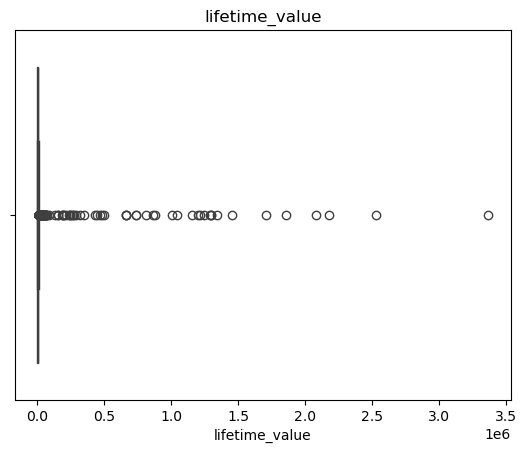

In [77]:
sns.boxplot(x=df["lifetime_value"])
plt.title("lifetime_value")
plt.show()

In [71]:
pd.set_option("display.max_columns", None)
df["lifetime_value"].describe().round(2)

count      14136.00
mean        6494.20
std        63387.80
min            0.00
25%          256.56
50%          859.94
75%         5119.65
max      3371260.00
Name: lifetime_value, dtype: float64

É clara a presença de valores extremos na variável `lifetime_value`. Com efeito, a análise da função `.describe()` evidencia uma forte assimetria positiva da distribuição, uma vez que a média (`mean = 6494.20`) é consideravelmente superior à mediana (`50% = 859.94`). Esta diferença é acompanhada por um valor máximo de `3371260.00`, bastante superior ao terceiro quartil (`75% = 5119.65`), o que sugere a existência de observações com valores de `lifetime_value` excecionalmente elevados.

In [72]:
df.sort_values("lifetime_value", ascending=False).head(20)

,member_id,age,gender,industry,base_country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value,tem_inconsistencia_temporal,n_erros
8166,CW008209,36,Female,Finance,Portugal,False,0.0,full_time,5,2021-01-01,NaT,2023-12-03,29.0,250.0,1.60,43.48,13,85.6,496.1,0,True,True,False,True,False,False,False,False,False,0.0,3371260.0,False,0
12436,CW012530,33,Male,Real Estate,Portugal,False,0.0,NaN,7,2021-01-18,2023-07-31,2023-07-28,3.0,710.0,5.38,60.87,52,407.5,0.0,0,True,False,False,True,True,False,False,False,False,3.0,2532335.0,False,0
9393,CW009446,27,Female,Finance,Portugal,False,0.0,private_office,7,2021-03-06,2023-11-08,2023-10-23,16.0,161.0,1.15,60.87,12,0.0,0.0,43,False,False,True,False,False,True,False,False,False,3.0,2181450.0,False,0
12556,CW012651,45,Female,Information Technology,Portugal,False,0.0,private_office,7,2021-08-17,2023-12-21,2023-12-20,1.0,716.0,5.85,60.87,52,77.7,0.0,0,True,False,False,True,True,True,False,True,False,2.0,2084722.0,False,0
1576,CW001578,28,Female,Finance,Portugal,False,0.0,private_office,7,2021-05-27,2023-05-29,2023-05-23,6.0,562.0,5.37,60.87,38,147.8,0.0,0,True,False,False,False,True,True,False,True,False,1.0,1861269.0,False,0
8975,CW009026,31,Female,Information Technology,NaN,False,0.0,private_office,7,2022-04-15,NaT,2023-12-31,1.0,454.0,5.08,60.87,45,46.3,49.5,0,True,True,False,True,True,False,False,True,False,3.0,1712153.0,False,0
10700,CW010771,31,Male,Design & Creative,France,True,3.0,dedicated_desk,5,2021-01-16,2023-12-31,2023-12-30,1.0,603.0,3.91,43.48,30,153.2,0.0,0,True,False,False,True,False,False,False,False,False,5.0,1453134.0,False,0
365,CW000366,27,Female,Legal,Portugal,False,0.0,dedicated_desk,5,2021-08-03,NaT,2023-12-30,2.0,555.0,4.41,43.48,41,123.3,0.0,0,True,False,False,True,True,True,True,False,False,3.0,1342807.0,False,0
11933,CW012021,26,Male,Marketing & PR,NaN,True,1.0,full_time,5,2021-05-19,2023-03-08,2023-03-04,4.0,158.0,1.68,43.48,20,253.2,58.9,60,True,True,True,False,True,False,False,False,False,2.0,1296617.0,False,0
3181,CW003189,44,Female,Other,NaN,False,0.0,dedicated_desk,5,2021-02-23,2023-11-28,2023-11-24,4.0,539.0,3.75,43.48,33,64.2,0.0,0,True,False,False,True,False,True,False,False,False,5.0,1294678.0,False,0


Analise-se as duas primeiras linhas na tentativa de estabelecer algum padrão e concluir sobre a razoabilidade dos valores enormescos associados a estes membros:

1. Uma sócia do setor de *Finance*, sediada em Portugal, aderiu ao espaço no primeiro dia de 2021 com um plano *full_time* (o segundo mais caro), que lhe permite utilizar o espaço cinco dias por semana. Na prática, utiliza-o em média 1,6 vezes por semana (250 visitas no total), não tem nenhuma renovação registada nem data de fim de inscrição, e a sua última visita foi no ínicio do mês de dezembro de 2023. Em cerca de três anos de inscrição (é este o prazo dado no enunciado), tem a si associado um *lifetime value* de 3 371 260 €, o que corresponderia a mais de 90 000 € por mês, valor que não é compatível com o perfil de utilização observado. Consideramos, por isso, que se trata de um erro de registo.
2. Um sócio do setor de *Real Estate*, também sediado em Portugal, com conta igualmente individual, aderiu ao espaço a 18 de janeiro de 2021. O plano registado não é conhecido, mas permite-lhe utilizar o espaço 7 dias por semana. Ainda que as 3 renovações registadas indiquem uma relação mais prolongada com o espaço do que no caso anterior, a inscrição teve início em 2021, o que limita o período de permanência a poucos anos. Um lifetime value de 2 532 335 € implicaria uma faturação mensal na ordem das dezenas de milhares de euros, valor incompatível com uma conta individual num espaço de cowork, mesmo com acesso diário. Consideramos, por isso, que também se trata de um erro de registo.

#### O problema do excesso de valores 0

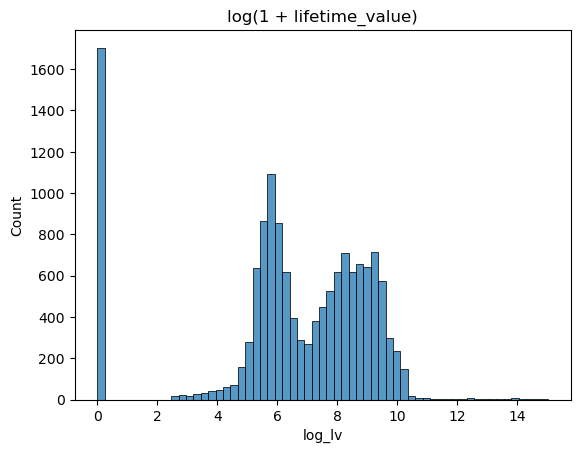

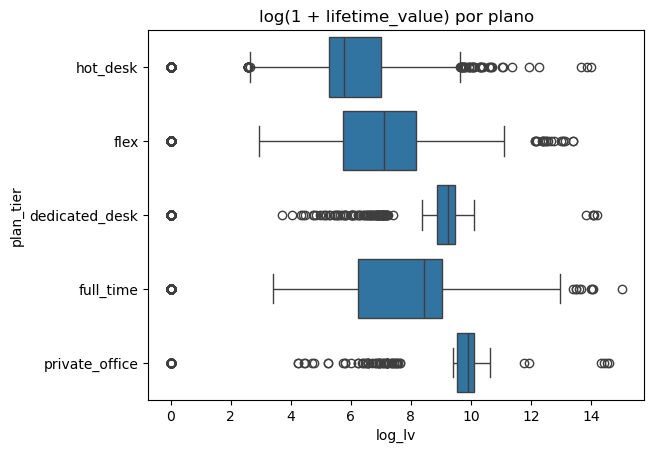

In [93]:
df["log_lv"] = np.log1p(df["lifetime_value"]) # we have to use 1 + lifetime_value because there are some zeros, and f(x)=log(x) is not defined at x=0.

# Histograma geral
sns.histplot(df["log_lv"])
plt.title("log(1 + lifetime_value)")
plt.show()

# Boxplot por plano
sns.boxplot(x=df["log_lv"], y=df["plan_tier"])
plt.title("log(1 + lifetime_value) por plano")
plt.show()

In [105]:
zeros = df["lifetime_value"] == 0

print("Zeros no total:", zeros.sum())
print("Com pelo menos uma visita:", (zeros & (df["total_visits"] > 0)).sum())
print("Com renovações:", (zeros & (df["n_renewals"] > 0)).sum())
print("Com renovações e conta individual:",
      (zeros & (df["n_renewals"] > 0) & (df["is_team_account"] == False)).sum())
print("Zeros de quem nunca o visitou:", (zeros & (df["total_visits"] == 0)).sum())

Zeros no total: 1704
Com pelo menos uma visita: 1693
Com renovações: 810
Com renovações e conta individual: 569
Zeros de quem nunca o visitou: 9


In [96]:
df["lifetime_value"].isna().sum()

np.int64(1014)

In [98]:
zeros_sem_renov = zeros & (df["n_renewals"] == 0)

print("Zeros sem renovações:", zeros_sem_renov.sum())
print(df.loc[zeros_sem_renov, "total_visits"].describe())

Zeros sem renovações: 882
count    881.000000
mean      40.365494
std       86.672347
min        0.000000
25%        5.000000
50%        8.000000
75%       24.000000
max      850.000000
Name: total_visits, dtype: float64


In [106]:
zero_invalido = (df["lifetime_value"] == 0) & (df["total_visits"] != 0).fillna(True)

df.loc[zero_invalido, "lifetime_value"] = pd.NA

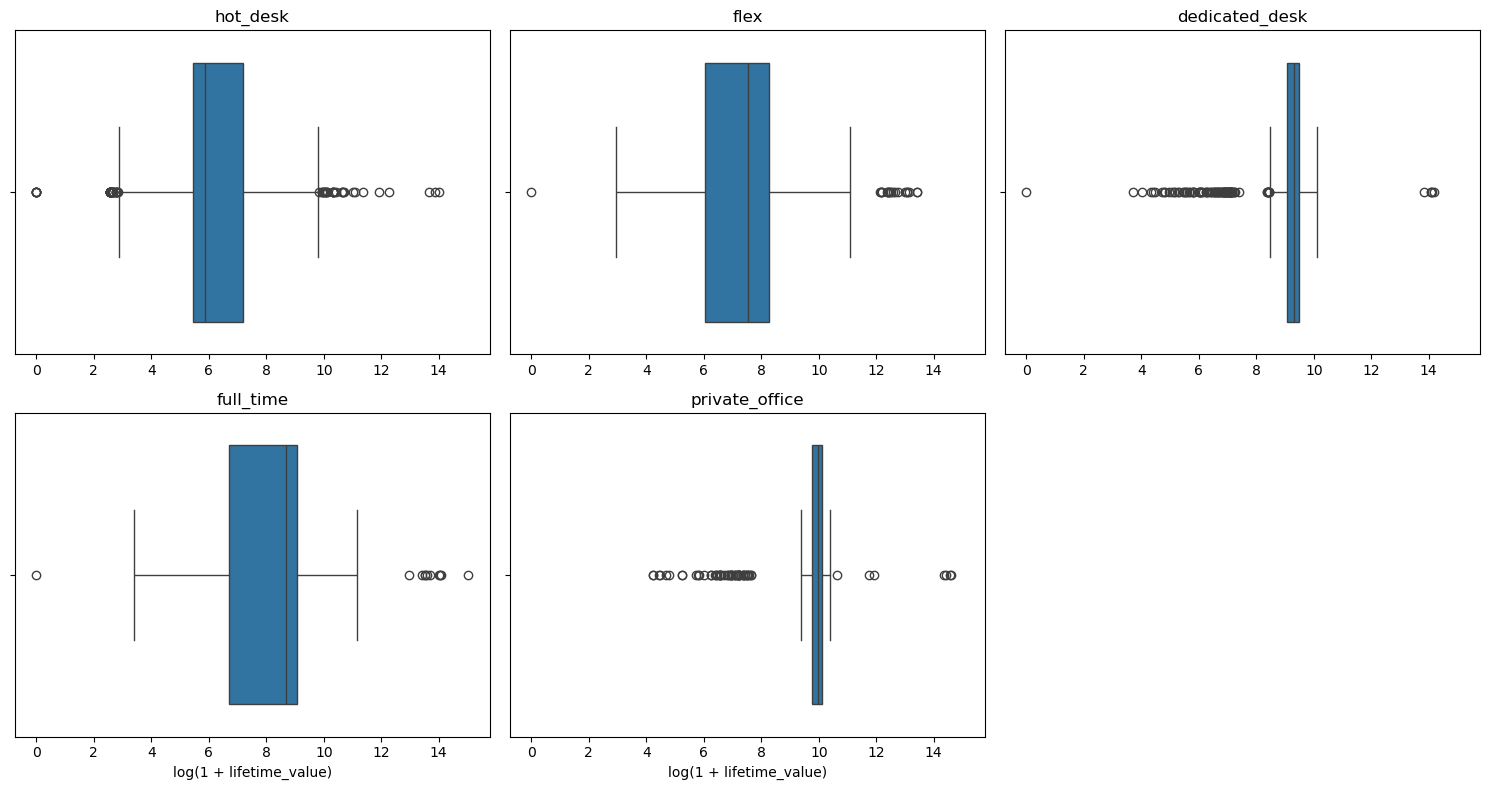

In [109]:
planos = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office"]

fig, axs = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
axs = axs.flatten()

for i, plano in enumerate(planos):
    dados = df.loc[df["plan_tier"] == plano, "log_lv"]
    sns.boxplot(x=dados, ax=axs[i])
    axs[i].set_title(plano)
    axs[i].set_xlabel("log(1 + lifetime_value)")
    axs[i].tick_params(labelbottom=True)   # mostra os números do eixo em todos

axs[5].axis("off")

plt.tight_layout()
plt.show()

Da análise do conjunto de *boxplots*, é praticamente imediato que os planos `dedicated_desk`e `private_office` são os que carecem de uma análise mais rigorosa, dado que apresentam valores altos tais que "deslocam" a distribuição para a direita, deixando a larga maioria das observações como *outliers* aparentes.

Analise-se cada uma destas variáveis individualmente:

In [110]:
# Meses entre a adesão e a última entrada
meses = (df["last_badge_swipe"] - df["membership_start"]).dt.days / 30

# Períodos com menos de 1 mês dariam divisões enganadoras
meses[meses < 1] = np.nan

df["receita_mensal"] = df["lifetime_value"] / meses

df.groupby("plan_tier", observed=True)["receita_mensal"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
plan_tier,,,,,,,,
hot_desk,2508.0,323.0,2107.7,0.0,128.8,152.4,215.3,78532.3
flex,3163.0,456.1,2162.2,0.0,197.5,223.6,270.9,39190.8
dedicated_desk,1166.0,645.3,2702.6,0.0,413.5,448.0,499.0,45829.6
full_time,1541.0,726.7,4069.5,0.0,325.0,368.8,437.1,94876.0
private_office,474.0,1501.9,7534.4,50.7,683.5,705.2,734.7,82183.3
